# Topic modeling
## Data preparation
Let's use the example of HCAI paper abstract. Each abstract is treated as a document, and the collection of abstracts forms our corpus.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.decomposition import LatentDirichletAllocation, NMF
from nltk.tokenize import MWETokenizer
from Jieshu_utils_for_tokenization import *
from nltk import word_tokenize
from nltk.corpus import stopwords


hcai_paper = pd.read_csv("/Users/jieswang/PycharmProjects/Human_centered_AI_in_papers_and_patents/data/00-open_alex_datasets/hcai_paper_dataset_dropped_duplicates_2026-10-12_15-12-22.csv").sort_values(by='citations', ascending=False).head(100)

# download stopwords
stop_words = set(stopwords.words('english'))

def remove_stop_words(tokens):
    pattern = re.compile(r'^[a-zA-Z0-9_]+$')
    return [t for t in tokens if re.match(pattern, t) and t.lower() not in stop_words]

mwes_updated = [
    'world wide web', 'neural network', 'deep learning', 'internet of thing',
    'real time', 'artificial intelligence', 'machine learning',
    'object oriented', 'support vector machine',
    'expert system', 'natural language', 'principal component analysis',
    'lightweight directory access protocol', 'social network',
    'stem cell', 'random forest', 'x ray', 'mobile phone', 'n gram',
    'non linear', 'ad hoc network', 'fuzzy logic', 'operating system'
    'genetic algorithm','supervised learning','unsupervised learning', 'semi supervised learning','facial recognition','face recognition',
    'generative adversarial network','type 1','supply chain','three dimensional','gradient descent', 'reinforcement learning',
    'pattern recognition','speech recognition', 'search engine','virtual reality','augment reality','user interface']

multi_words_list_updated = [tuple(i.lower().split()) for i in mwes_updated]

multi_words_tokenizer = MWETokenizer(multi_words_list_updated).tokenize

tokenize_pipeline = [str.lower, clean, normalize, word_tokenize, multi_words_tokenizer, lemmatize, remove_stop_words]

def apply_pipeline(text, pipeline):
    for func in pipeline:
        text = func(text)
    return text

hcai_paper['abstract_tokenized'] = hcai_paper['abstract'].apply(lambda x: apply_pipeline(x, tokenize_pipeline))

print("abstract tokenized")

# Inspect the data
print(hcai_paper.shape)
print(hcai_paper["abstract_tokenized"].head())

# Remove missing and empty documents
df = hcai_paper.dropna(subset=["abstract_tokenized"]).copy()

df = df[
    df["abstract_tokenized"].apply(
        lambda x: isinstance(x, list) and len(x) > 0
    )
].copy()

# Convert tokens into strings
df["text"] = df["abstract_tokenized"].apply(
    lambda tokens: " ".join(tokens)
)

df["text"].head()

abstract tokenized
(100, 11)
7108    [explainable, artificial_intelligence, ai, att...
7170    [stay, top, get, tough, challenging, due, fast...
7047    [well, design, technology, offer, high, level,...
5942    [guide, explain, focus, rigor, relevance, qual...
6509    [abstract, educational, technology, innovation...
Name: abstract_tokenized, dtype: object


7108    explainable artificial_intelligence ai attract...
7170    stay top get tough challenging due fast growin...
7047    well design technology offer high level human ...
5942    guide explain focus rigor relevance qualitativ...
6509    abstract educational technology innovation lev...
Name: text, dtype: str

## Create document-term matrices
LDA and NMF generally use different text representations in introductory applications:
- LDA: Word counts (Bag of Words)
- NMF: TF-IDF scores

In [2]:
# Bag of Words for LDA
count_vectorizer = CountVectorizer(
    max_df=0.95,
    min_df=2,
    max_features=2000
)

X_count = count_vectorizer.fit_transform(df["text"])

# TF-IDF for NMF
tfidf_vectorizer = TfidfVectorizer(
    max_df=0.95,
    min_df=2,
    max_features=2000
)

X_tfidf = tfidf_vectorizer.fit_transform(df["text"])

print("Count matrix:", X_count.shape)
print("TF-IDF matrix:", X_tfidf.shape)

Count matrix: (100, 1539)
TF-IDF matrix: (100, 1539)


## Classic topic modeling
### Topic modeling using LDA
Latent Dirichlet Allocation (LDA) is a probabilistic topic model. It assumes documents contain mixtures of latent topics, and each topic is represented by a probability distribution over words.

For this demonstration, we will identify five topics.

In [3]:
# Number of topics
n_topics = 5

# Train LDA model
lda_model = LatentDirichletAllocation(
    n_components=n_topics,
    random_state=42,
    max_iter=20
)

lda_model.fit(X_count)

,"n_components n_components: int, default=10Number of topics... versionchanged:: 0.19 ``n_topics`` was renamed to ``n_components``",5
,"max_iter max_iter: int, default=10The maximum number of passes over the training data (aka epochs).It only impacts the behavior in the :meth:`fit` method, and not the:meth:`partial_fit` method.",20
,"random_state random_state: int, RandomState instance or None, default=NonePass an int for reproducible results across multiple function calls.See :term:`Glossary <random_state>`.",42
,"doc_topic_prior doc_topic_prior: float, default=NonePrior of document topic distribution `theta`. If the value is None,defaults to `1 / n_components`.In [1]_, this is called `alpha`.",None
,"topic_word_prior topic_word_prior: float, default=NonePrior of topic word distribution `beta`. If the value is None, defaultsto `1 / n_components`.In [1]_, this is called `eta`.",None
,"learning_method learning_method: {'batch', 'online'}, default='batch'Method used to update `_component`. Only used in :meth:`fit` method.In general, if the data size is large, the online update will be muchfaster than the batch update.Valid options:- 'batch': Batch variational Bayes method. Use all training data in each EM update. Old `components_` will be overwritten in each iteration.- 'online': Online variational Bayes method. In each EM update, use mini-batch of training data to update the ``components_`` variable incrementally. The learning rate is controlled by the ``learning_decay`` and the ``learning_offset`` parameters... versionchanged:: 0.20 The default learning method is now ``""batch""``.",'batch'
,"learning_decay learning_decay: float, default=0.7It is a parameter that control learning rate in the online learningmethod. The value should be set between (0.5, 1.0] to guaranteeasymptotic convergence. When the value is 0.0 and batch_size is``n_samples``, the update method is same as batch learning. In theliterature, this is called kappa.",0.7
,"learning_offset learning_offset: float, default=10.0A (positive) parameter that downweights early iterations in onlinelearning. It should be greater than 1.0. In the literature, this iscalled tau_0.",10.0
,"batch_size batch_size: int, default=128Number of documents to use in each EM iteration. Only used in onlinelearning.",128
,"evaluate_every evaluate_every: int, default=-1How often to evaluate perplexity. Only used in `fit` method.set it to 0 or negative number to not evaluate perplexity intraining at all. Evaluating perplexity can help you check convergencein training process, but it will also increase total training time.Evaluating perplexity in every iteration might increase training timeup to two-fold.",-1
,"total_samples total_samples: int, default=1e6Total number of documents. Only used in the :meth:`partial_fit` method.",1000000.0


In [4]:
# Display the top words for each topic
def display_topics(model, feature_names, n_words=10):
    for topic_idx, topic in enumerate(model.components_):
        top_indices = topic.argsort()[-n_words:][::-1]
        top_words = [feature_names[i] for i in top_indices]

        print(f"Topic {topic_idx + 1}:")
        print(", ".join(top_words))
        print()

# Display LDA topics
display_topics(
    lda_model,
    count_vectorizer.get_feature_names_out()
)

Topic 1:
future, industry, research, would, technology, also, could, study, challenge, need

Topic 2:
robot, social, environment, agent, propose, mobile, ai, data, collaboration, model

Topic 3:
ai, use, technology, model, healthcare, research, development, based, center, team

Topic 4:
ai, learning, education, generative, educational, research, study, use, technology, model

Topic 5:
ai, system, speech, design, approach, technology, artificial_intelligence, use, center, research



#### interpretation of the topics

\- Topic 1: AI Development and Emerging Challenges

- Focuses on future directions of AI research, technological development, industrial applications, and emerging challenges.
- Relatively broad and less clearly defined due to generic keywords.

\- Topic 2: Social Robotics and Human–Robot Interaction

- Focuses on intelligent robots, autonomous agents, and their interactions with humans and social environments.
- Emphasizes collaboration, mobility, and social interaction.

\- Topic 3: AI Applications in Healthcare

- Focuses on the development and application of AI technologies in healthcare.
- May include AI-assisted healthcare services, decision-making, and clinical applications.

\- Topic 4: AI in Education and Learning

- Focuses on AI applications in educational environments, particularly generative AI.
- Includes AI-assisted teaching, learning, and educational technologies.

\- Topic 5: AI System Design and Speech Technologies

- Focuses on the design and development of AI systems, particularly speech-related technologies.
- May include speech recognition, conversational interfaces, and human–AI interaction.

Note: Topics 1, 3, and 5 are somewhat ambiguous and would benefit from examining representative abstracts before finalizing their labels.

### Topic modeling using NMF
Non-negative Matrix Factorization (NMF) decomposes a non-negative document-term matrix into document-topic and topic-word matrices.

Unlike LDA, NMF is not a probabilistic topic model. It identifies patterns of word co-occurrence through matrix factorization.

In [5]:
# Train NMF model
nmf_model = NMF(
    n_components=n_topics,
    random_state=42,
    init="nndsvda",
    max_iter=500
)

nmf_model.fit(X_tfidf)

,"n_components n_components: int or {'auto'} or None, default='auto'Number of components. If `None`, all features are kept.If `n_components='auto'`, the number of components is automatically inferredfrom W or H shapes... versionchanged:: 1.4 Added `'auto'` value... versionchanged:: 1.6 Default value changed from `None` to `'auto'`.",5
,"init init: {'random', 'nndsvd', 'nndsvda', 'nndsvdar', 'custom'}, default=NoneMethod used to initialize the procedure.Valid options:- `None`: 'nndsvda' if n_components <= min(n_samples, n_features), otherwise random.- `'random'`: non-negative random matrices, scaled with: `sqrt(X.mean() / n_components)`- `'nndsvd'`: Nonnegative Double Singular Value Decomposition (NNDSVD) initialization (better for sparseness)- `'nndsvda'`: NNDSVD with zeros filled with the average of X (better when sparsity is not desired)- `'nndsvdar'` NNDSVD with zeros filled with small random values (generally faster, less accurate alternative to NNDSVDa for when sparsity is not desired)- `'custom'`: Use custom matrices `W` and `H` which must both be provided... versionchanged:: 1.1 When `init=None` and n_components is less than n_samples and n_features defaults to `nndsvda` instead of `nndsvd`.",'nndsvda'
,"max_iter max_iter: int, default=200Maximum number of iterations before timing out.",500
,"random_state random_state: int, RandomState instance or None, default=NoneUsed for initialisation (when ``init`` == 'nndsvdar' or'random'), and in Coordinate Descent. Pass an int for reproducibleresults across multiple function calls.See :term:`Glossary <random_state>`.",42
,"solver solver: {'cd', 'mu'}, default='cd'Numerical solver to use:- 'cd' is a Coordinate Descent solver.- 'mu' is a Multiplicative Update solver... versionadded:: 0.17 Coordinate Descent solver... versionadded:: 0.19 Multiplicative Update solver.",'cd'
,"beta_loss beta_loss: float or {'frobenius', 'kullback-leibler', 'itakura-saito'}, default='frobenius'Beta divergence to be minimized, measuring the distance between Xand the dot product WH. Note that values different from 'frobenius'(or 2) and 'kullback-leibler' (or 1) lead to significantly slowerfits. Note that for beta_loss <= 0 (or 'itakura-saito'), the inputmatrix X cannot contain zeros. Used only in 'mu' solver... versionadded:: 0.19",'frobenius'
,"tol tol: float, default=1e-4Tolerance of the stopping condition.",0.0001
,"alpha_W alpha_W: float, default=0.0Constant that multiplies the regularization terms of `W`. Set it to zero(default) to have no regularization on `W`... versionadded:: 1.0",0.0
,"alpha_H alpha_H: float or ""same"", default=""same""Constant that multiplies the regularization terms of `H`. Set it to zero tohave no regularization on `H`. If ""same"" (default), it takes the same value as`alpha_W`... versionadded:: 1.0",'same'
,"l1_ratio l1_ratio: float, default=0.0The regularization mixing parameter, with 0 <= l1_ratio <= 1.For l1_ratio = 0 the penalty is an elementwise L2 penalty(aka Frobenius Norm).For l1_ratio = 1 it is an elementwise L1 penalty.For 0 < l1_ratio < 1, the penalty is a combination of L1 and L2... versionadded:: 0.17 Regularization parameter *l1_ratio* used in the Coordinate Descent solver.",0.0
,"verbose verbose: int, default=0Whether to be verbose.",0


In [6]:
display_topics(
    nmf_model,
    tfidf_vectorizer.get_feature_names_out()
)

Topic 1:
ai, hcai, healthcare, system, technology, organization, center, perspective, ml, process

Topic 2:
industry, aec, technology, digital, challenge, manufacturing, twin, global, technological, provide

Topic 3:
xai, explanation, explainability, explainable, evaluation, user, healthcare, ai, method, study

Topic 4:
network, research, data, agent, smart, social, deep_learning, design, model, team

Topic 5:
generative, learning, education, genai, educational, ai, tool, student, teacher, teaching



#### Interpretation of the topics

- Topic 1: Human-Centered AI in Healthcare and Organizations
    - Focuses on the development and implementation of human-centered AI in healthcare and organizational settings.
    - Emphasizes organizational perspectives, technological integration, and processes for adopting AI and machine learning.
- Topic 2: AI and Digital Transformation in Industry
    - Focuses on AI applications in industrial settings, particularly architecture, engineering, and construction (AEC) and manufacturing.
    - Emphasizes digital technologies, digital twins, and challenges associated with technological transformation.
- Topic 3: Explainable AI (XAI) and Human-Centered Evaluation
    - Focuses on AI explainability, interpretability, and the evaluation of AI explanations.
    - Emphasizes user perspectives, evaluation methods, and applications in healthcare.
- Topic 4: Intelligent Networks and Multi-Agent Systems
    - Focuses on AI-driven networks, intelligent agents, and deep learning applications.
    - May include social networks, smart systems, collaborative agents, and network-based modeling.
- Topic 5: Generative AI in Education and Teaching
    - Focuses on the applications of generative AI in educational settings.
    - Emphasizes AI-powered educational tools, student learning, teacher support, and AI-assisted teaching practices.

Note: Topics 1, 3, and 5 are relatively coherent and directly relevant to HCAI. Topic 2 represents an industry-specific application domain, while Topic 4 is broader and would benefit from examining representative abstracts to clarify its central research focus.
### Visualize the top words in each topic
We can create bar charts showing the highest-weighted words for each topic.

In [ ]:
def plot_topics(model, feature_names, model_name, n_words=10):

    fig, axes = plt.subplots(
        1, n_topics,
        figsize=(20, 5)
    )

    for topic_idx, topic in enumerate(model.components_):

        top_indices = topic.argsort()[-n_words:]

        words = [feature_names[i] for i in top_indices]
        weights = topic[top_indices]

        axes[topic_idx].barh(words, weights)
        axes[topic_idx].set_title(f"Topic {topic_idx + 1}")
        axes[topic_idx].set_xlabel("Word Weight")

    plt.suptitle(f"{model_name}: Top Words by Topic", fontsize=16)
    plt.tight_layout()
    plt.show()

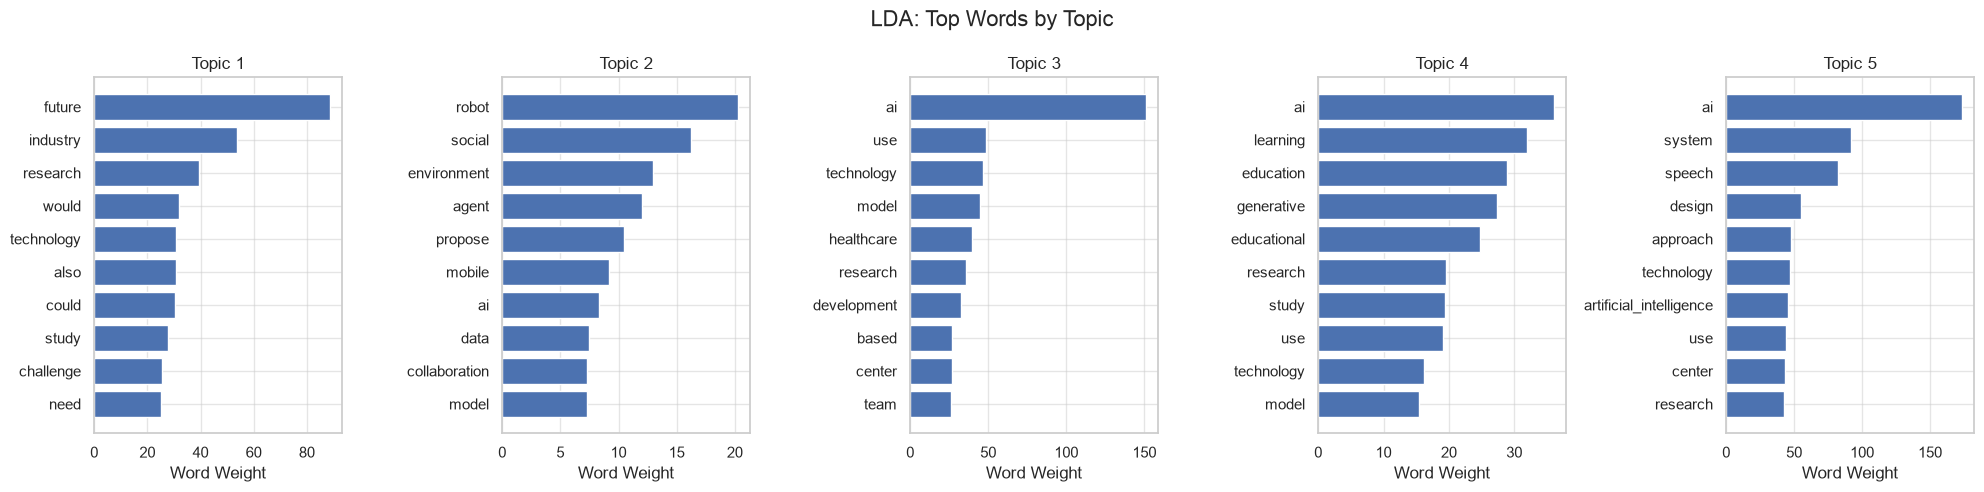

In [11]:
sns.set_theme(style="whitegrid")
plot_topics(
    lda_model,
    count_vectorizer.get_feature_names_out(),
    "LDA"
)

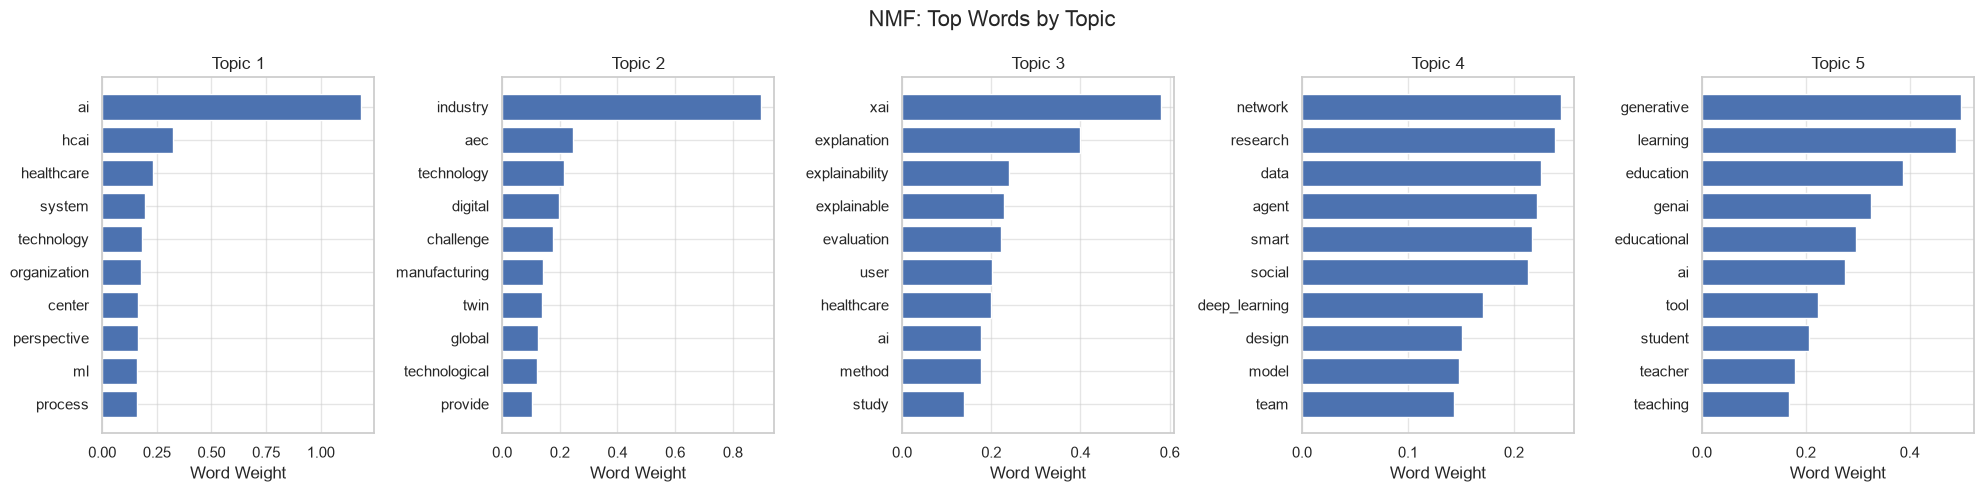

In [12]:
plot_topics(
    nmf_model,
    tfidf_vectorizer.get_feature_names_out(),
    "NMF"
)

### Assign a dominant topic to each paper
Both methods can estimate how strongly each paper is associated with each topic.
LDA

In [13]:
# Document-topic distributions
lda_doc_topics = lda_model.transform(X_count)

# Assign dominant topic
df["lda_topic"] = lda_doc_topics.argmax(axis=1) + 1

# View topic assignments
df[["text", "lda_topic"]].head()

,text,lda_topic
7108,explainable artificial_intelligence ai attract...,5
7170,stay top get tough challenging due fast growin...,1
7047,well design technology offer high level human ...,5
5942,guide explain focus rigor relevance qualitativ...,5
6509,abstract educational technology innovation lev...,1


In [14]:
# Document-topic weights
nmf_doc_topics = nmf_model.transform(X_tfidf)

# Assign dominant topic
df["nmf_topic"] = nmf_doc_topics.argmax(axis=1) + 1

# View topic assignments
df[["text", "lda_topic", "nmf_topic"]].head()

,text,lda_topic,nmf_topic
7108,explainable artificial_intelligence ai attract...,5,3
7170,stay top get tough challenging due fast growin...,1,2
7047,well design technology offer high level human ...,5,4
5942,guide explain focus rigor relevance qualitativ...,5,4
6509,abstract educational technology innovation lev...,1,5


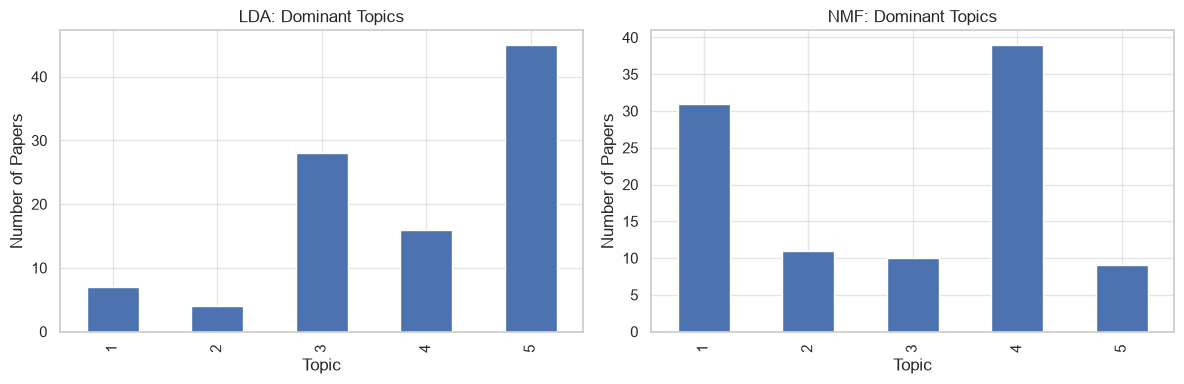

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

df["lda_topic"].value_counts().sort_index().plot(
    kind="bar",
    ax=axes[0],
    title="LDA: Dominant Topics"
)

df["nmf_topic"].value_counts().sort_index().plot(
    kind="bar",
    ax=axes[1],
    title="NMF: Dominant Topics"
)

axes[0].set_xlabel("Topic")
axes[0].set_ylabel("Number of Papers")

axes[1].set_xlabel("Topic")
axes[1].set_ylabel("Number of Papers")

plt.tight_layout()
plt.show()

### Examine representative papers for each topic
Top words alone may not be enough to interpret a topic. Researchers should also examine documents strongly associated with it.

For example, identify the three papers most strongly associated with LDA Topic 1.

In [16]:
# Choose topic 1 (index 0)
topic_idx = 0

# Find top 3 papers associated with this topic
top_indices = lda_doc_topics[:, topic_idx].argsort()[-3:][::-1]

# Display their abstracts
for i in top_indices:
    print(f"Topic Score: {lda_doc_topics[i, topic_idx]:.3f}")
    print(df.iloc[i]["text"][:500])
    print("-" * 60)

Topic Score: 0.999
moment crisis may serve critical juncture imagine alternative future become increasingly volatile precarious unsettled time pandemic climate emergency rise inequality ever loom digital r evolution great need opportunity develop theory guide society towards future potentiality theorize yet exist central task would develop methodological strategy make future amenable empirical study quite ambitious essay seek take one many step advocate search future act disciplined imagination become input theory
------------------------------------------------------------
Topic Score: 0.996
industry 4 0 introduce new technological advance additive manufacturing artificial_intelligence ai augment reality ar cyber physical system cps blockchain cybersecurity many also help organisation take challenge like demand fluctuation market volatility industry 4 0 also interconnection computer material ai minimal human intervention decision making although industry 4 0 tremendous potential indus

## Embedding-based topic modeling

BERTopic is a topic modeling approach that uses sentence embeddings, clustering, and class-based TF-IDF (c-TF-IDF) to identify topics in text.

Unlike LDA and NMF, which rely primarily on word-frequency patterns, BERTopic uses semantic embeddings to group documents with similar meanings.

### Train the model

In [2]:
from bertopic import BERTopic

documents = df["abstract"].fillna("").astype(str).tolist()

# Initialize the model
topic_model = BERTopic(
    embedding_model="all-MiniLM-L6-v2",
    min_topic_size=5,
    verbose=True
)

# Fit the model
topics, probabilities = topic_model.fit_transform(documents)

W1106 16:29:27.021000 45122 .venv/lib/python3.14/site-packages/torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.
2026-11-06 16:29:27,517 - BERTopic - Embedding - Transforming documents to embeddings.


Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

Batches:   0%|          | 0/4 [00:00<?, ?it/s]

2026-11-06 16:29:28,225 - BERTopic - Embedding - Completed ✓
2026-11-06 16:29:28,225 - BERTopic - Dimensionality - Fitting the dimensionality reduction algorithm
2026-11-06 16:29:31,676 - BERTopic - Dimensionality - Completed ✓
2026-11-06 16:29:31,676 - BERTopic - Cluster - Start clustering the reduced embeddings
2026-11-06 16:29:31,679 - BERTopic - Cluster - Completed ✓
2026-11-06 16:29:31,680 - BERTopic - Representation - Fine-tuning topics using representation models.
2026-11-06 16:29:31,695 - BERTopic - Representation - Completed ✓


Unlike the earlier LDA and NMF examples, BERTopic automatically identifies the number of topics based on the clustering results.

The min_topic_size=5 parameter specifies the approximate minimum cluster size. It can be increased for larger datasets.
### Examine the topics

In [3]:
# Display topic information
topic_info = topic_model.get_topic_info()

topic_info

,Topic,Count,Name,Representation,Representative_Docs
0,-1,30,-1_the_of_and_to,"[the, of, and, to, in, we, that, for, human, is]","[The architecture, engineering, and constructi..."
1,0,15,0_and_to_the_of,"[and, to, the, of, human, hcai, in, ai, that, ...",[The rapid advancements in artificial intellig...
2,1,12,1_the_industry_and_of,"[the, industry, and, of, in, to, human, is, th...",[Fish constitute important high protein produc...
3,2,12,2_and_of_speech_the,"[and, of, speech, the, to, on, for, in, ai, ge...",[Artificial Intelligence (AI) in Education cla...
4,3,10,3_and_of_the_ai,"[and, of, the, ai, in, to, healthcare, health,...",[Background: Medicine is becoming an increasin...
5,4,9,4_ai_human_the_and,"[ai, human, the, and, to, of, in, we, research...",[Introduction: With the advancement of technol...
6,5,6,5_the_of_explainability_to,"[the, of, explainability, to, explanations, an...",[Artificial intelligence (AI) and especially r...
7,6,6,6_deep_learning_the_in,"[deep, learning, the, in, and, of, to, researc...",[Deep learning has exploded in the public cons...


The results include the topic number, document count, representative keywords, and topic name.

**Note**: Topic -1 represents documents classified as outliers that were not assigned to any of the identified topics.

Display the top 10 words for Topic 0:

In [19]:
topic_model.get_topic(0)

[('the', np.float64(0.0686965635103771)),
 ('to', np.float64(0.06313241599356612)),
 ('and', np.float64(0.06206117544006079)),
 ('of', np.float64(0.0587767663308454)),
 ('we', np.float64(0.04147255267966985)),
 ('human', np.float64(0.04106912130602545)),
 ('in', np.float64(0.03973200051464535)),
 ('that', np.float64(0.03933138072567504)),
 ('ai', np.float64(0.03822266722976383)),
 ('for', np.float64(0.03213443506861031))]

### Visualize the topics

In [4]:
topic_model.visualize_topics()

In [5]:
# visualize top keywords
topic_model.visualize_barchart(
    top_n_topics=5,
    n_words=10
)

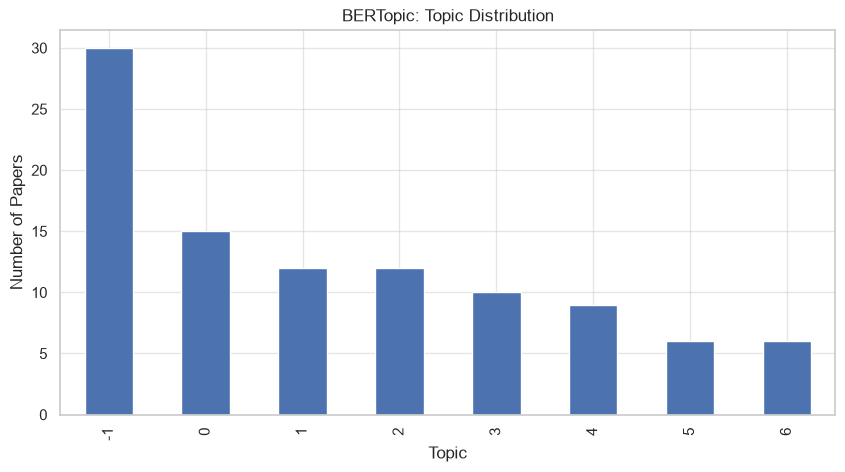

In [7]:
# visualize topics sizes
# Add topic assignments to the DataFrame

sns.set_theme(style="whitegrid")
df["bertopic_topic"] = topics

# Count documents assigned to each topic
df["bertopic_topic"].value_counts().sort_index().plot(
    kind="bar",
    figsize=(10, 5),
    title="BERTopic: Topic Distribution"
)

plt.xlabel("Topic")
plt.ylabel("Number of Papers")
plt.show()

### Examine representative papers
We can also examine the papers assigned to each topic to help interpret its meaning.

In [8]:
# View document-level topic assignments
doc_info = topic_model.get_document_info(documents)

# Display the first few papers
doc_info[["Document", "Topic", "Name"]].head()

,Document,Topic,Name
0,Explainable artificial intelligence (AI) is at...,5,5_the_of_explainability_to
1,Staying at the top is getting tougher and more...,1,1_the_industry_and_of
2,Well-designed technologies that offer high lev...,0,0_and_to_the_of
3,"This guide explains the focus, rigor, and rele...",3,3_and_of_the_ai
4,Abstract Educational technology innovations le...,2,2_and_of_speech_the


In [9]:
# Examine the first three papers assigned to Topic 0:
doc_info[doc_info["Topic"] == 0][
    ["Document", "Name"]
].head(3)

,Document,Name
2,Well-designed technologies that offer high lev...,0_and_to_the_of
5,Abstract We propose a central role for work de...,0_and_to_the_of
10,This article attempts to bridge the gap betwee...,0_and_to_the_of
